In [1]:
#%pip install -q requests pydantic python-dotenv pandas matplotlib

In [59]:
import os, re, sys, json, time, ast, operator, subprocess, csv
from pathlib import Path
from dataclasses import dataclass, field
import requests
import pandas as pd
import matplotlib.pyplot as plt
from pydantic import BaseModel, Field, ValidationError

# Шаг 1. Датасет свежих вопросов

In [47]:
DATA = Path("/kaggle/working/data")
DATA.mkdir(parents=True, exist_ok=True)

START_PATH = Path("/kaggle/input/datasets/olegkaalex/hw-data/fresh_2026.jsonl")
CSV_PATH = Path("/kaggle/input/datasets/olegkaalex/hw-data/new_data_2026.csv")
CUSTOM_JSONL = Path("/kaggle/working/data/fresh_custom.jsonl")

OUT_PATH = Path("/kaggle/working/data/fresh.jsonl")

In [31]:
def load_jsonl(path: Path):
    rows = []
    for line in path.read_text(encoding="utf-8").splitlines():
        if line.strip():
            rows.append(json.loads(line))
    return rows


def load_csv(path: Path):
    rows = []
    with path.open(encoding="cp1251", newline="") as f:
        reader = csv.DictReader(f, delimiter=";")
        for row in reader:
            rows.append(row)
    return rows

In [56]:
new_rows = load_csv(CSV_PATH)

CUSTOM_JSONL.write_text(
    "\n".join(json.dumps(r, ensure_ascii=False) for r in new_rows) + "\n",
    encoding="utf-8"
)
print(f"Записано {len(new_rows)} записей в {CUSTOM_JSONL}")

Записано 20 записей в /kaggle/working/data/fresh_custom.jsonl


In [43]:
!python /kaggle/input/datasets/olegkaalex/hw-data/check_fresh.py /kaggle/working/data/fresh_custom.jsonl

записей: 20, проблем: 0


In [44]:
!python /kaggle/input/datasets/olegkaalex/hw-data/check_fresh.py /kaggle/working/data/fresh_custom.jsonl --sonnet

записей: 20, проблем: 0

Sonnet без инструментов: 3 из 20 верно, 15%. Потрачено $0.037
критерий свежести пройден
  fresh-126: В скольких городах проходил Чемпионат мира по футболу 2026? -> 16
  fresh-127: Какие страны автоматически вышли в финальную часть Чемпионата мира 2026? -> США, Канада и Мексика — как страны-орган
  fresh-129: Кем поставляются шины, которые все команды используют в ходе сезона Формулы-1 в 2026 году? -> Pirelli


# Шаг 2. Агент

In [60]:
try:
    from dotenv import load_dotenv
    load_dotenv()
except ImportError:
    pass
try:
    from kaggle_secrets import UserSecretsClient
    os.environ.setdefault("OPENROUTER_API_KEY", UserSecretsClient().get_secret("OPENROUTER_API_KEY"))
except Exception:
    pass
assert os.getenv("OPENROUTER_API_KEY"), "нет ключа: положите его в .env рядом с ноутбуком или в Kaggle Secrets"

CHAT_URL = "https://openrouter.ai/api/v1/chat/completions"
HEADERS = {"Authorization": f"Bearer {os.environ['OPENROUTER_API_KEY']}",
           "HTTP-Referer": "https://postypashki.ru", "X-Title": "agents-course-seminar01"}

MODELS = {"cheap": "openai/gpt-4o-mini", "mid": "anthropic/claude-haiku-4.5", "strong": "anthropic/claude-sonnet-4.6"}

COLORS = {"violet": "#5436A3", "amber": "#F09000", "teal": "#00838F", "red": "#C43C3C", "grey": "#787882"}

# DATA = next((p for p in [Path("qa_data"), Path("/kaggle/input/datasets/artmakar04/"), Path("/kaggle/input/seminar01-data/data")]
#              if (p / "compare_10.jsonl").exists()), Path("qa-data"))
TRACES, IMG = Path("traces"), Path("img")
TRACES.mkdir(exist_ok=True)
IMG.mkdir(exist_ok=True)

In [61]:
@dataclass
class Ledger:
    calls: list = field(default_factory=list)

    def add(self, tag, model, usage, seconds=0.0):
        p, c = usage.get("prompt_tokens", 0), usage.get("completion_tokens", 0)
        cost = usage.get("cost") or 0.0
        self.calls.append({"tag": tag, "model": model.split("/")[-1], "prompt": p, "completion": c,
                           "cost": cost, "seconds": round(seconds, 2)})
        return cost

    @property
    def total(self):
        return sum(c["cost"] for c in self.calls)

    def table(self):
        df = pd.DataFrame(self.calls)
        return df.groupby(["tag", "model"]).agg(calls=("cost", "size"), prompt=("prompt", "sum"),
                                                completion=("completion", "sum"), cost=("cost", "sum"),
                                                seconds=("seconds", "sum")).round(5)

ledger = Ledger()

In [62]:
def post_with_retry(body, attempts=3):
    for attempt in range(attempts):
        r = requests.post(CHAT_URL, json=body, headers=HEADERS, timeout=120)
        if r.status_code == 200:
            return r.json()
        if r.status_code in (429, 500, 502, 503) and attempt < attempts - 1:
            time.sleep(1.5 * (attempt+1))
            continue
        raise RuntimeError(f"HTTP {r.status_code} : {r.text[:5000]}")

In [63]:
def chat(messages, model, tools=None, tag="chat", temperature=None):
    body = {"model": model, "messages": messages, "usage": {"include": True}}
    if tools:
        body["tools"] = tools
        body["tool_choice"] = "auto"
    if temperature is not None:
        body["temperature"] = temperature
    started = time.perf_counter()
    data = post_with_retry(body)
    ledger.add(tag, model, data.get("usage") or {}, time.perf_counter() - started)
    return data["choices"][0]["message"]

In [64]:
msg = chat([{"role": "user", "content": "Ответь одним словом: какого цвета небо?"}], MODELS["cheap"], tag="hello")
msg["content"], ledger.calls[-1]

('Синее.',
 {'tag': 'hello',
  'model': 'gpt-4o-mini',
  'prompt': 18,
  'completion': 4,
  'cost': 5.1e-06,
  'seconds': 1.05})

In [65]:
class Answer(BaseModel):
    reasoning: str = Field(description="ход решения в два-три предложения")
    final: str = Field(description="только итоговый ответ: число или короткая фраза")

SCHEMA_PROMPT = "Отвечай строго одним JSON-объектом по этой схеме, без текста вокруг, строки в одну линию, без лишних отступов, \t, \n:\n{schema}"

def json_from(text):
    m = re.search(r"\{.*\}", text or "", re.S)
    if not m:
        raise ValueError("в ответе нет JSON")
    return json.loads(m.group(0), strict=False)

In [66]:
Answer.model_json_schema()

{'properties': {'reasoning': {'description': 'ход решения в два-три предложения',
   'title': 'Reasoning',
   'type': 'string'},
  'final': {'description': 'только итоговый ответ: число или короткая фраза',
   'title': 'Final',
   'type': 'string'}},
 'required': ['reasoning', 'final'],
 'title': 'Answer',
 'type': 'object'}

In [67]:
schema=Answer
SCHEMA_PROMPT.format(schema=json.dumps(schema.model_json_schema(), ensure_ascii=False))

'Отвечай строго одним JSON-объектом по этой схеме, без текста вокруг, строки в одну линию, без лишних отступов, \t, \n:\n{"properties": {"reasoning": {"description": "ход решения в два-три предложения", "title": "Reasoning", "type": "string"}, "final": {"description": "только итоговый ответ: число или короткая фраза", "title": "Final", "type": "string"}}, "required": ["reasoning", "final"], "title": "Answer", "type": "object"}'

In [68]:
def ask_structured(question, model, schema=Answer, attempts=3):
    messages = [
        {"role": "system", "content": SCHEMA_PROMPT.format(schema=json.dumps(schema.model_json_schema(), ensure_ascii=False))},
        {"role": "user", "content": question}
    ]
    for _ in range(attempts):
        msg = chat(messages, model, tag="struct")
        try:
            return schema.model_validate(json_from(msg["content"]))
        except (ValidationError, ValueError) as e:
            messages += [msg, {"role": "user", "content": f"Ответ не прошел проверку на структуру: {e}. Верни ответ по строгой JSON схеме"}]
    raise ValueError("Модель не справилась")

In [69]:
def normalize(text):
    text = re.sub(r"[^\w\s]", " ", str(text).lower().replace(",", ""))
    text = re.sub(r"\b(a|an|the)\b", " ", text)
    return " ".join(text.split())

def is_correct(task, answer):
    if task["source"] == "gsm8k":
        nums = re.findall(r"-?\d+(?:\.\d+)?", str(answer).replace(",", ""))
        return bool(nums) and abs(float(nums[-1]) - float(task["answer"])) < 1e-6
    return normalize(task["answer"]) in normalize(answer)

def summary(config, model, n, correct, cost, steps, seconds=0.0):
    return {"config": config, "model": model.split("/")[-1], "n": n, "accuracy": round(correct / n, 2),
            "cost_per_task": round(cost / n, 5), "cost_per_correct": round(cost / correct, 5) if correct else float("inf"),
            "avg_steps": round(steps, 2), "avg_seconds": round(seconds, 1)}

def compare_models(tasks, models):
    rows = []
    for name, model in models.items():
        before, correct, started = ledger.total, 0, time.perf_counter()
        for task in tasks:
            try:
                correct += is_correct(task, ask_structured(task["question"], model).final)
            except Exception:
                pass
        rows.append(summary("без инструментов, JSON", model, len(tasks), correct, ledger.total - before, 1,
                            (time.perf_counter() - started) / len(tasks)))
    return pd.DataFrame(rows)

def compare_chart(df):
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
    axes[0].bar(df["model"], df["accuracy"] * 100, color=COLORS["violet"])
    axes[0].set_ylabel("доля верных, %")
    axes[0].set_ylim(0, 105)
    axes[1].bar(df["model"], df["cost_per_correct"] * 100, color=COLORS["amber"])
    axes[1].set_ylabel("цена верного ответа, центы")
    axes[2].bar(df["model"], df["avg_seconds"], color=COLORS["teal"])
    axes[2].set_ylabel("секунд на задачу")
    for ax in axes:
        ax.tick_params(axis="x", labelrotation=12)
        ax.grid(alpha=0.3, axis="y")
    fig.tight_layout()
    return fig

## Инструменты

In [70]:
TOOLS = {}

def register(fn, args_model, description):
    TOOLS[fn.__name__] = {"fn": fn, "args": args_model, "schema": {"type": "function", "function": {
        "name": fn.__name__, "description": description, "parameters": args_model.model_json_schema()}}}

In [71]:
OPS = {ast.Add: operator.add, ast.Sub: operator.sub, ast.Mult: operator.mul, ast.Div: operator.truediv,
       ast.Pow: operator.pow, ast.USub: operator.neg, ast.Mod: operator.mod}

def evaluate(node):
    if isinstance(node, ast.Constant) and isinstance(node.value, (int, float)):
        return node.value
    if isinstance(node, ast.BinOp) and type(node.op) in OPS:
        return OPS[type(node.op)](evaluate(node.left), evaluate(node.right))
    if isinstance(node, ast.UnaryOp) and type(node.op) in OPS:
        return OPS[type(node.op)](evaluate(node.operand))
    raise ValueError("допустимы только числа и арифметика")

class CalcArgs(BaseModel):
    expr: str = Field(description="арифметическое выражение, например 17*23+5")

def calculator(expr: str) -> str:
    try:
        val = evaluate(ast.parse(expr.replace(",", "."), mode="eval").body)
        return str(int(val)) if float(val).is_integer() else f"{val:.4f}".rstrip("0")
    except Exception as e:
        return f"ошибка вычисления: {e}"

In [72]:
register(calculator, CalcArgs, "Считает арифметическое выражение: числа, скобки, + - * / ** %")
json.dumps(TOOLS["calculator"]["schema"], ensure_ascii=False, indent=1)

'{\n "type": "function",\n "function": {\n  "name": "calculator",\n  "description": "Считает арифметическое выражение: числа, скобки, + - * / ** %",\n  "parameters": {\n   "properties": {\n    "expr": {\n     "description": "арифметическое выражение, например 17*23+5",\n     "title": "Expr",\n     "type": "string"\n    }\n   },\n   "required": [\n    "expr"\n   ],\n   "title": "CalcArgs",\n   "type": "object"\n  }\n }\n}'

In [73]:
EN_WIKI = "https://en.wikipedia.org/w/api.php"
RU_WIKI = "https://ru.wikipedia.org/w/api.php"

WIKI_HEADERS = {"User-Agent": "agents-course-seminar01/1.0 (https://postypashki.ru; educational project)"}

def wiki(params, lang="en", attempts=3):
    url = RU_WIKI if lang == "ru" else EN_WIKI

    for attempt in range(attempts):
        r = requests.get(
            url,
            params={**params, "format": "json"},
            headers=WIKI_HEADERS,
            timeout=15,
        )

        if r.status_code == 200 and r.headers.get("content-type", "").startswith("application/json"):
            return r.json()["query"]

        time.sleep(1.0 + attempt)

    raise RuntimeError(f"Википедия ответила {r.status_code}")

In [74]:
class SearchArgs(BaseModel):
    query: str = Field(description="Короткий поисковый запрос: имя, название, термин")


def ru_web_search(query: str) -> str:
    hits = wiki(
        {
            "action": "query",
            "list": "search",
            "srsearch": query,
            "srlimit": 1,
        },
        lang="ru",
    )["search"]

    if not hits:
        return "No data"

    title = hits[0]["title"]

    pages = wiki(
        {
            "action": "query",
            "prop": "extracts",
            "explaintext": 1,
            "exintro": 1,
            "titles": title,
        },
        lang="ru",
    )["pages"]

    text = " ".join(next(iter(pages.values())).get("extract", "").split())

    return f"[{title}] {text[:5000]}"

In [75]:
register(
    ru_web_search,
    SearchArgs,
    "Ищет статью в русскоязычной Википедии и возвращает её вступление. Используй для русских вопросов о свежих событиях."
)

In [76]:
class PageFindArgs(BaseModel):
    title: str = Field(description="Точное название статьи в русской Википедии, например 'GPT-6'")
    keywords: str = Field(description="Ключевые слова через запятую, которые нужно найти в тексте статьи")


def page_find(title: str, keywords: str) -> str:
    try:
        pages = wiki(
            {
                "action": "query",
                "prop": "extracts",
                "explaintext": 1,
                "titles": title,
            },
            lang="ru",
        )["pages"]

        page = next(iter(pages.values()))
        text = page.get("extract", "")

        if not text.strip():
            return "No page text"

        kws = [
            k.strip().lower()
            for k in re.split(r"[,;]", keywords)
            if k.strip()
        ]

        chunks = []
        for part in re.split(r"\n+|(?<=[.!?])\s+", text):
            part = " ".join(part.split())
            if not part:
                continue

            low = part.lower()
            if any(k in low for k in kws):
                chunks.append(part)

        if not chunks:
            return "No matching lines"

        result = "\n".join(chunks[:20])
        return f"[{title}]\n{result[:5000]}"

    except Exception as e:
        return f"ошибка page_find: {e}"

In [77]:
register(
    page_find,
    PageFindArgs,
    "Читает полный текст статьи русской Википедии по точному названию и возвращает фрагменты, где встречаются ключевые слова. Используй после ru_web_search, если вступления статьи недостаточно."
)

In [78]:
class ExecArgs(BaseModel):
    code: str = Field(description="код на Python; результат надо напечатать через print")

def python_exec(code: str) -> str:
    try:
        r = subprocess.run([sys.executable, "-I", "-c", code], capture_output=True, text=True, timeout=5)
    except subprocess.TimeoutExpired:
        return "Код превысил 5 сек"
    out = (r.stdout + r.stderr).strip()
    return out[:5000] if out else "Код исполнился но результат пустой"


In [79]:
register(python_exec, 
         ExecArgs, 
         "Выполняет код на Python в отдельном процессе и возвращает то, что он напечатал"
)

### Тесты


In [80]:
# calculator
assert calculator("2+2") == "4"
assert calculator("2**10") == "1024"
assert "ошибка" in calculator("__import__('os')")

# ru_web_search
assert ru_web_search("Чемпионат мира по футболу 2026").startswith("[")
assert ru_web_search("qwxzv 1234567 nonsense") == "No data"

# page_find
assert "No" not in page_find("Чемпионат мира по футболу 2026", "16 городов")[:50]
assert page_find("СтраницаКоторойНет123456", "что-то") in ["No page text", "No matching lines"] or "ошибка" in page_find("СтраницаКоторойНет123456", "что-то")

# python_exec
assert python_exec("print(sum(range(10)))") == "45"
assert "ZeroDivisionError" in python_exec("1/0")
assert "Код превысил 5 сек" in python_exec("import time; time.sleep(10)")

"инструменты работают"

'инструменты работают'

In [81]:
SYSTEM = ("Ты решаешь задачи. Если нужно посчитать или найти факт, вызывай инструменты, а не угадывай. "
          "Когда ответ готов, напиши его последней строкой в формате FINAL: <ответ>. "
          "Для числовых задач в FINAL только число, для вопросов о фактах короткая фраза.")

@dataclass
class Run:
    question: str
    answer: str
    steps: int
    messages: list
    cost: float = 0.0
    seconds: float = 0.0

def looped(seen, calls):
    keys = [(c["function"]["name"], c["function"]["arguments"]) for c in calls]
    repeated = any(k in seen for k in keys)
    seen.update(keys)
    return repeated

def finish(model, messages, step):
    del messages[-1]
    messages.append({"role": "user", "content": "Инструменты больше недоступны. Ответь по тому, что уже известно, последней строкой FINAL: <ответ>."})
    msg = chat(messages, model, tag="agent")
    messages.append(msg)
    return msg.get("content") or "", step + 1

In [82]:
def agent_loop(messages, model, tool_names, max_steps):
    seen = set()
    for step in range(1, max_steps + 1):
        msg = chat(messages, model, tools=[TOOLS[n]["schema"] for n in tool_names] or None, tag='agent')
        messages.append(msg)
        calls = msg.get("tool_calls") or []

        if not calls:
            return msg.get("content") or "", step
        if looped(seen, calls) or step == max_steps:
            return finish(model, messages, step)

        messages += [run_tool(c) for c in calls]


In [83]:
def run_tool(call):
    name = call["function"]["name"]

    try:
        spec = TOOLS[name]
        args = spec["args"].model_validate_json(call["function"]["arguments"])
        result = spec["fn"](**args.model_dump())
    except Exception as e:
        result = f"НЕ удалось вызвать инструмент {name}: {e}"
    return {"role": "tool", "tool_call_id" : call["id"], "content": str(result)[:2000]}

In [84]:
def agent(question, model, tool_names, max_steps=8):
    messages = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": question}]
    before, started = ledger.total, time.perf_counter()
    answer, steps = agent_loop(messages, model, tool_names, max_steps)
    return Run(question, answer, steps, messages, ledger.total - before, time.perf_counter() - started)

def show_trace(run):
    for m in run.messages[1:]:
        calls = "; ".join(f"{c['function']['name']}{c['function']['arguments']}" for c in m.get("tool_calls") or [])
        text = " ".join((m.get("content") or "").split())[:180]
        print(f"{m['role']:9s}| {text} {calls}")
    print(f"шагов: {run.steps}, цена: {run.cost * 100:.3f} ¢, время: {run.seconds:.1f} c")

In [87]:
def final_answer(text):
    m = re.search(r"FINAL:\s*(.+)", text or "")
    return m.group(1).strip() if m else (text or "").strip()

def run_tasks(tasks, model, tool_names, config):
    folder = TRACES / config / model.split("/")[-1]
    folder.mkdir(parents=True, exist_ok=True)
    rows = []
    for task in tasks:
        try:
            run = agent(task["question"], model, tool_names)
        except Exception as e:
            run = Run(task["question"], f"ошибка: {e}", 0, [])
        ok = is_correct(task, final_answer(run.answer))
        rows.append({"config": config, "model": model.split("/")[-1], "id": task["id"], "source": task["source"],
                     "correct": ok, "steps": run.steps, "tool_calls": sum(m["role"] == "tool" for m in run.messages),
                     "cost": run.cost, "seconds": round(run.seconds, 1), "answer": final_answer(run.answer)[:60], "gold": task["answer"]})
        (folder / f"{task['id']}.json").write_text(json.dumps({"task": task, "answer": run.answer, "correct": ok, "cost": run.cost,
                                                              "messages": run.messages}, ensure_ascii=False, indent=1), encoding="utf-8")
    return pd.DataFrame(rows)

def report(results):
    rows = [summary(config, model, len(df), int(df["correct"].sum()), df["cost"].sum(), df["steps"].mean(), df["seconds"].mean())
            for (config, model), df in results.groupby(["config", "model"])]
    return pd.DataFrame(rows).sort_values("cost_per_task").reset_index(drop=True)

def money_chart(table, path="img/money_quality.png"):
    fig, ax = plt.subplots(figsize=(8, 5))
    for _, r in table.iterrows():
        color = COLORS["red"] if "каскад" in r["config"] else COLORS["amber"] if "sonnet" in r["model"] else COLORS["violet"]
        ax.scatter(r["cost_per_task"] * 100, r["accuracy"] * 100, s=110, color=color)
        ax.annotate(f"{r['config']}\n{r['model']}", (r["cost_per_task"] * 100, r["accuracy"] * 100),
                    fontsize=8, xytext=(6, 4), textcoords="offset points")
    ax.set_xscale("log")
    ax.set_xlabel("цена задачи, центы (логарифмическая шкала)")
    ax.set_ylabel("доля верных ответов, %")
    ax.grid(alpha=0.3)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    return fig

def steps_chart(results):
    g = results.groupby("config").agg(steps=("steps", "mean"), tool_calls=("tool_calls", "mean"), seconds=("seconds", "mean"))
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
    g[["steps", "tool_calls"]].plot.bar(ax=axes[0], color=[COLORS["violet"], COLORS["teal"]], rot=12)
    axes[0].set_ylabel("в среднем на задачу")
    g["seconds"].plot.bar(ax=axes[1], color=COLORS["amber"], rot=12)
    axes[1].set_ylabel("секунд на задачу")
    for ax in axes:
        ax.grid(alpha=0.3, axis="y")
        ax.set_xlabel("")
    fig.tight_layout()
    return fig


In [88]:
CONFIGS = {
    "strong без инструментов": (MODELS["strong"], []),
    "cheap без инструментов": (MODELS["cheap"], []),
    "cheap только ru_search": (MODELS["cheap"], ["ru_web_search"]),
    "cheap ru_search + page_find": (MODELS["cheap"], ["ru_web_search", "page_find"]),
    "mid лучший агент": (MODELS["mid"], ["ru_web_search", "page_find", "calculator", "python_exec"]),
}

In [85]:
tasks = load_jsonl(Path("/kaggle/working/data/fresh_custom.jsonl"))
tasks[0]

{'id': 'fresh-126',
 'source': 'fresh',
 'question': 'В скольких городах проходил Чемпионат мира по футболу 2026?',
 'answer': '16',
 'evidence': 'Изначально были определены 23 города-кандидата, из которых в период с 2020 по 2022\xa0год были отобраны 16 городов, где в итоге прошёл чемпионат (2 в Канаде, 3 в Мексике и 11 в США).',
 'page': 'Чемпионат мира по футболу 2026',
 'url': 'https://ru.wikipedia.org/wiki/%D0%A7%D0%B5%D0%BC%D0%BF%D0%B8%D0%BE%D0%BD%D0%B0%D1%82_%D0%BC%D0%B8%D1%80%D0%B0_%D0%BF%D0%BE_%D1%84%D1%83%D1%82%D0%B1%D0%BE%D0%BB%D1%83_2026',
 'sonnet_answer': '',
 'agent_ok': ''}

In [89]:
run = agent(
    tasks[0]["question"],
    MODELS["cheap"],
    ["ru_web_search", "page_find", "calculator", "python_exec"],
    max_steps=8,
)

show_trace(run)
print(run.answer)
print("gold:", tasks[0]["answer"])
print("correct:", is_correct(tasks[0], final_answer(run.answer)))

user     | В скольких городах проходил Чемпионат мира по футболу 2026? 
assistant|  ru_web_search{"query":"Чемпионат мира по футболу 2026 города"}
tool     | [Чемпионат мира по футболу 2026] Чемпионат мира по футболу 2026 года (англ. 2026 FIFA World Cup) — 23-й чемпионат мира по футболу ФИФА, финальная часть которого прошла с 11 июня по 
assistant| Чемпионат мира по футболу 2026 проходил в 16 городах. FINAL: 16 
шагов: 2, цена: 0.023 ¢, время: 2.9 c
Чемпионат мира по футболу 2026 проходил в 16 городах.

FINAL: 16
gold: 16
correct: True


In [90]:
frames = []

for config, (model, tools) in CONFIGS.items():
    print("running:", config)
    frames.append(run_tasks(tasks, model, tools, config))

results = pd.concat(frames, ignore_index=True)
table = report(results)

table

running: strong без инструментов
running: cheap без инструментов
running: cheap только ru_search
running: cheap ru_search + page_find
running: mid лучший агент


,config,model,n,accuracy,cost_per_task,cost_per_correct,avg_steps,avg_seconds
0,cheap без инструментов,gpt-4o-mini,20,0.10,0.00004,0.00045,1.00,1.5
1,cheap ru_search + page_find,gpt-4o-mini,20,0.60,0.00032,0.00053,3.00,4.8
2,cheap только ru_search,gpt-4o-mini,20,0.40,0.00035,0.00086,3.20,5.7
3,strong без инструментов,claude-sonnet-4.6,20,0.10,0.00262,0.02620,1.00,3.4
4,mid лучший агент,claude-haiku-4.5,20,0.35,0.00859,0.02455,1.95,3.9


In [107]:
results.to_csv("/kaggle/working/results_raw.csv", index=False)
Path("/kaggle/working/results.md").write_text(
    table.to_markdown(index=False),
    encoding="utf-8"
)

979

In [96]:
results[["config", "model", "id", "correct", "steps", "tool_calls", "cost", "seconds", "answer", "gold"]][60:80]

,config,model,id,correct,steps,tool_calls,cost,seconds,answer,gold
60,cheap ru_search + page_find,gpt-4o-mini,fresh-126,True,2,1,0.000195,3.0,16,16
61,cheap ru_search + page_find,gpt-4o-mini,fresh-127,True,6,5,0.000996,11.6,"США, Канада и Мексика.","США, Канада и Мексика"
62,cheap ru_search + page_find,gpt-4o-mini,fresh-128,False,6,5,0.000666,10.1,информация недоступна,Джордж Расселл
63,cheap ru_search + page_find,gpt-4o-mini,fresh-129,True,3,2,0.000284,4.7,Pirelli,Pirelli
64,cheap ru_search + page_find,gpt-4o-mini,fresh-130,False,2,1,0.000126,2.7,Шанхай,В Шанхае
65,cheap ru_search + page_find,gpt-4o-mini,fresh-131,True,3,2,0.000237,4.2,SPD Bank Oriental Sports Center,SPD Bank Oriental Sports Center
66,cheap ru_search + page_find,gpt-4o-mini,fresh-132,False,2,1,0.000138,2.8,4 по 26 июля 2026 года.,с 4 по 26 июля 2026 года
67,cheap ru_search + page_find,gpt-4o-mini,fresh-133,False,4,3,0.000328,6.7,Информация недоступна.,3333 км
68,cheap ru_search + page_find,gpt-4o-mini,fresh-134,True,3,2,0.000339,4.3,3 сентября 2026 года,3 сентября 2026 года
69,cheap ru_search + page_find,gpt-4o-mini,fresh-135,False,4,3,0.000346,5.6,100000,более чем 100 000


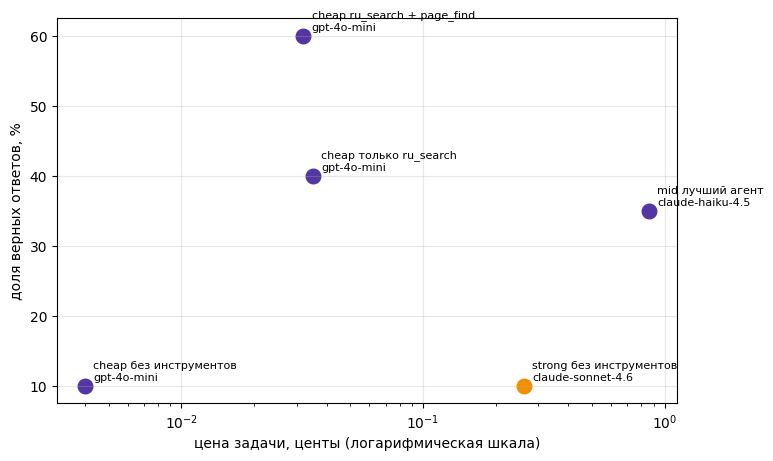

In [100]:
money_chart(table);

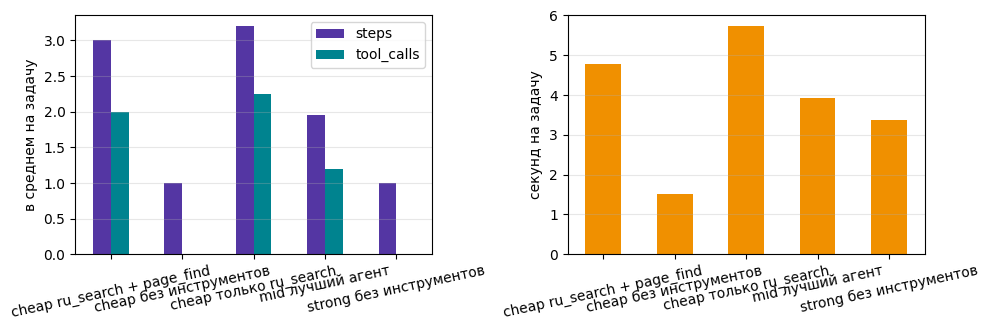

In [108]:
steps_chart(results);


In [105]:
target_id = "fresh-128"
path = TRACES / "cheap ru_search + page_find" / "gpt-4o-mini" / f"{target_id}.json"

trace = json.loads(path.read_text(encoding="utf-8"))

show_trace(
    Run(
        trace["task"]["question"],
        trace["answer"],
        sum(m["role"] == "assistant" for m in trace["messages"]),
        trace["messages"],
        trace["cost"]
    )
)

user     | Кто одержал победу в первой гонке сезона Формулы-1 в 2026 году? 
assistant|  ru_web_search{"query":"Формула-1 2026 первая гонка победитель"}
tool     | [Формула-1 в сезоне 2026] Сезон 2026 года — сезон Формулы-1, в рамках которого проводится 77-й чемпионат мира по автогонкам в классе «Формула-1». Международной автомобильной федера 
assistant|  page_find{"title":"Формула-1 в сезоне 2026","keywords":"первая гонка победитель"}
tool     | No matching lines 
assistant|  ru_web_search{"query":"Формула-1 2026 чемпионат результаты первой гонки"}
tool     | [Формула-1 в сезоне 2026] Сезон 2026 года — сезон Формулы-1, в рамках которого проводится 77-й чемпионат мира по автогонкам в классе «Формула-1». Международной автомобильной федера 
assistant|  page_find{"title":"Формула-1 в сезоне 2026","keywords":"результаты Гран-при"}
tool     | [Формула-1 в сезоне 2026] == Результаты Гран-при == 
assistant|  ru_web_search{"query":"результаты первой гонки Формулы-1 2026"}
tool     | [Формула-1 

In [106]:
target_id = "fresh-133"
path = TRACES / "cheap ru_search + page_find" / "gpt-4o-mini" / f"{target_id}.json"

trace = json.loads(path.read_text(encoding="utf-8"))

show_trace(
    Run(
        trace["task"]["question"],
        trace["answer"],
        sum(m["role"] == "assistant" for m in trace["messages"]),
        trace["messages"],
        trace["cost"]
    )
)

user     | Сколько составила общая протяжённость дистанции Тур де Франс 2026? 
assistant|  ru_web_search{"query":"Тур де Франс 2026 дистанция"}
tool     | [Тур де Франс 2026] 113-й выпуск Тур де Франс — шоссейного гранд-тура по дорогам Франции и Испании. Гонка прошла с 4 по 26 июля 2026 года в рамках Мирового тура UCI 2026. Победу в  
assistant|  page_find{"title":"Тур де Франс 2026","keywords":"дистанция"}
tool     | No matching lines 
assistant|  ru_web_search{"query":"Тур де Франс 2026 протяжённость"}
tool     | [Тур де Франс] «Тур де Франс» (фр. Le Tour de France) — шоссейная многодневная велогонка, один из трёх гранд-туров. Самая известная и престижная велосипедная гонка мира, проводимая 
assistant| К сожалению, я не нашёл информацию о протяжённости дистанции Тур де Франс 2026. Возможно, эта информация ещё не была опубликована. FINAL: Информация недоступна. 
шагов: 4, цена: 0.033 ¢, время: 0.0 c
